# Plotting notebook

0) Plot original graph and perturbation in hyp disk

1) Plot nodes at distance < d from node i in hyp disk

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.patches as mpatches
import os
import pandas as pd
import networkx as nx
import datetime
import random
import plotly.express as px
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from hypnetperturb.utils import *
from hypnetperturb.embedding.coalescent_embedding import *
from hypnetperturb.embedding.distance import *
from hypnetperturb.visualization import *
from hypnetperturb.metrics.kNdist_score import *
from hypnetperturb.perturb_network import *
from hypnetperturb.generate_network import *

ModuleNotFoundError: No module named 'seaborn'

## 0) Plot original graph and perturbation

In [ ]:
 # Embedding parameters 
embedding_parameters_dict = {
'pre_weight':True,  
'binarize':True,
'dim_red_method':'ISOMAP',   
'eq_adj':True, 
'eta_r':0.1,
'beta_r':0.8,
'weight_r':False,
'res_dict':False
}

In [ ]:
## PARS
N = 20 #number of nodes
kl = 8 #k lattice
pr = 0.1 #p rewiring
mag= 20/100
k = 3
node_colors = np.array(N*['#545454'])
node_sizes =  np.array(N*[0.1])

## Original graph generation and embedding
G = nx.watts_strogatz_graph(N,kl,pr)
Y_G = coalescent_embedding_2D(G, **embedding_parameters_dict)

In [ ]:
## Pick most central node (for viz purposes)

r_G = np.sqrt(Y_G[:,0]**2+Y_G[:,1]**2)
ind = np.argsort(r_G)[0] #the second most central actually
ind = np.argsort(r_G)[19]
# find its nearest points in the original graph embedding
D_matrix = hyp_dist_matrix(Y_G,Y_G)
np.fill_diagonal(D_matrix,np.inf)
ind_kN = k_argmin(D_matrix[:,ind],k)
#ind_kN = np.setdiff1d(k_argmin(D_matrix[:,ind_most_central],k+1),ind_most_central)
edgelist = np.array([[ind,ind_kN[i]] for i in range(len(ind_kN))])
edgelist_colors = np.array(len(edgelist)*['#282828'])
# color them
node_colors[ind]='#0F0F0F'
node_colors[ind_kN[0]]= '#0000EE'
edgelist_colors[0]='#0000EE'
node_colors[ind_kN[1]]='#DC143C'
edgelist_colors[1]='#DC143C'
node_colors[ind_kN[2]]='#228B22'
edgelist_colors[2]='#228B22'
#node_colors[ind_kN[3]]='#473C8B'
#edgelist_colors[3]='#6959CD

In [ ]:
## Plot
Y_G = native_to_unitnative(Y_G)

Pdisk_G = plot_Pdisk_embedding(Y_G, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)
#Pdisk_G.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-o.svg'%(k))

## Perturbed graph generation and embedding
G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[ind]) 
Y_G_p = coalescent_embedding_2D(G_p, **embedding_parameters_dict)
Y_G_p = native_to_unitnative(Y_G_p)
Pdisk_G_p = plot_Pdisk_embedding(Y_G_p, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)
#Pdisk_G_p.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-p%.2f.svg'%(k,mag))

R =  1.0
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1]
R =  1.0
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1]


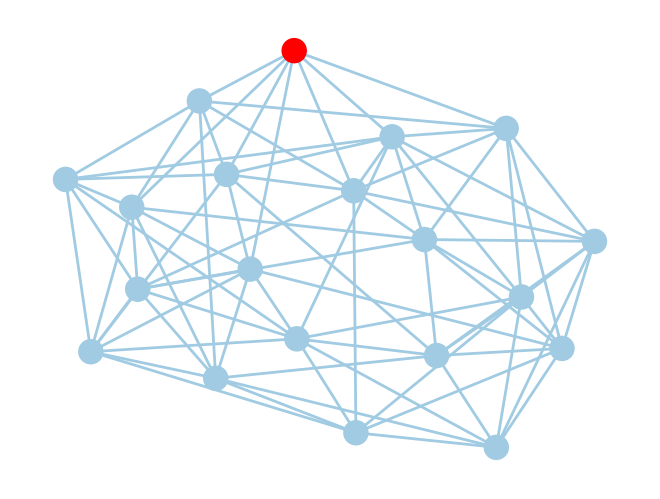

In [ ]:
pos = nx.spring_layout(G, seed=63)  # Seed layout for reproducibility
color_nodes = ["#A0CBE2"]*N
color_nodes[nodes_p_dict['nodes_perturbed'][0]]='red'
color_edges = "#A0CBE2"
options = {
    "node_color": color_nodes,
    "edge_color": color_edges,
    "width": 2,
    "edge_cmap": plt.cm.Blues,
    "with_labels": False,
}
nx.draw(G, pos, **options)
plt.show()

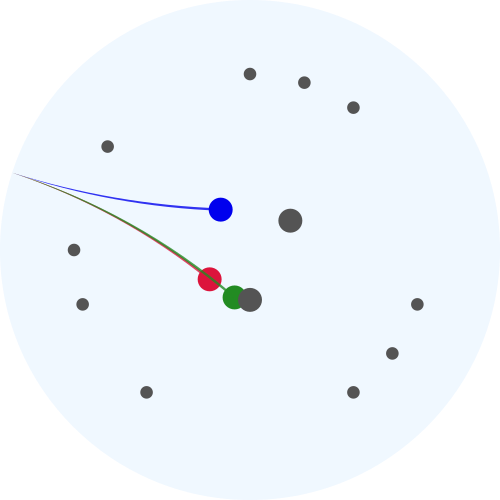

In [ ]:
Pdisk_G

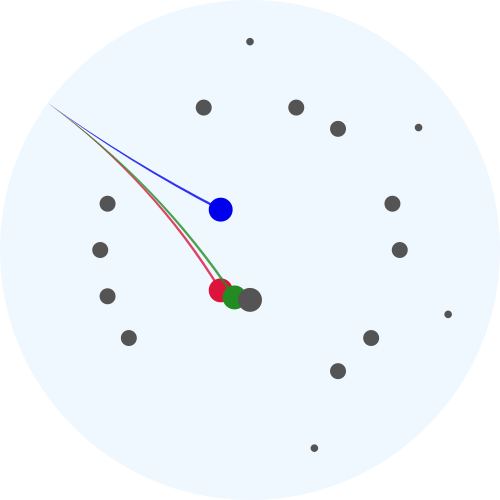

In [ ]:
Pdisk_G_p

## 1) Plot nodes at distance < d from node i
    - a central node
    - a peripherical node

In [ ]:
 # Embedding parameters 
embedding_parameters_dict = {
'pre_weight':True,  
'binarize':True,
'dim_red_method':'ISOMAP',   
'eq_adj':True, 
'eta_r':0.1,
'beta_r':0.8,
'weight_r':False,
'res_dict':False
}

In [ ]:
# pars
#-----
N = 50 #number of nodes
kl = 8 #k lattice
pr = 0.1 #p rewiring
mag=20/100
k = 3
node_colors = np.array(N*['black'])
node_sizes = np.array(N*[0.1])

## Original graph generation and embedding
G = nx.watts_strogatz_graph(N,kl,pr)
Y_G = coalescent_embedding_2D(G, **embedding_parameters_dict)

## Pick most central node (for viz purposes)
r_G = np.sqrt(Y_G[:,0]**2+Y_G[:,1]**2)
th_G = np.arctan2(Y_G[:,1], Y_G[:,0])

In [ ]:
colormap = 'tab20' 
norm = Normalize(vmin=0, vmax=N)
sm = ScalarMappable(norm=norm, cmap=colormap)
#colors = sm.to_rgba(x_t[:,i])
colors = [plt.cm.get_cmap(colormap)(norm(value))[:3] for value in range(N)]
colors = [plt.cm.colors.rgb2hex(color) for color in colors]

/var/folders/qh/cptr0vq561x2dc130rnhsmy80000gq/T/ipykernel_93620/2779250122.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = [plt.cm.get_cmap(colormap)(norm(value))[:3] for value in range(N)]


R =  32.18875824868201


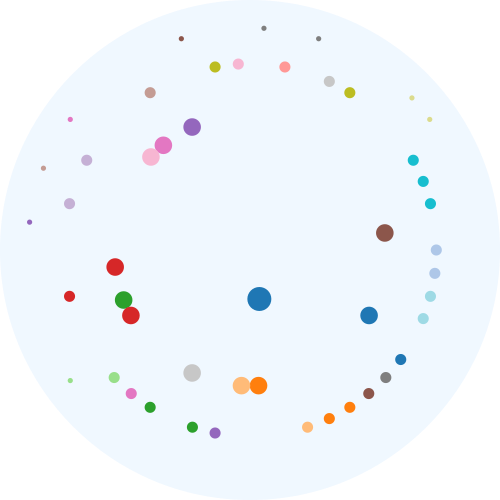

In [ ]:
xy_coalescent = coalescent_embedding_2D(G, **embedding_parameters_dict)
plot_Pdisk_embedding_n(xy_coalescent, node_colors=colors, sizes=np.array(N*[0.1]))

In [ ]:
#ind1 = np.argsort(th_G)[0] #the second most central actually
#ind2 = np.argsort(th_G)[3]

# find its nearest points in the original graph embedding
D_matrix = hyp_dist_matrix(Y_G,Y_G)
print(D_matrix)
np.fill_diagonal(D_matrix,0)
#ind_kN = k_argmin(D_matrix[:,ind],k)
#ind_kN = np.setdiff1d(k_argmin(D_matrix[:,ind_most_central],k+1),ind_most_central)

b = 1

indc = np.argsort(r_G)[0] #central
indc_ball =np.where(D_matrix[:,indc]<np.average(D_matrix)/b)[0]
indp = np.argsort(r_G)[12] #peripheric
indp_ball =np.where(D_matrix[:,indp]<np.average(D_matrix)/b)[0]

edgelistc = np.array([[indc,indc_ball[j]] for j in range(len(indc_ball))])
edgelistc_colors = np.array(len(edgelistc)*['#0000EE'])
edgelistp = np.array([[indp,indp_ball[j]] for j in range(len(indp_ball))])
edgelistp_colors = np.array(len(edgelistp)*['#DC143C'])

edgelist = np.append(edgelistc,edgelistp, axis=0)
edgelist_colors = np.append(edgelistc_colors,edgelistp_colors, axis=0)

[[ 0.         36.00775245 22.25820143 ... 39.83598648 37.39009637
  36.00775245]
 [36.00775245  0.         28.45464837 ... 46.57045185 44.68187729
  43.8775381 ]
 [22.25820143 28.45464837  0.         ... 29.9319048  29.20541765
  28.9926637 ]
 ...
 [39.83598648 46.57045185 29.9319048  ...  0.         45.68237853
  46.03242866]
 [37.39009637 44.68187729 29.20541765 ... 45.68237853  0.
  42.49519418]
 [36.00775245 43.8775381  28.9926637  ... 46.03242866 42.49519418
   0.        ]]


In [ ]:
## Plot
Y_poincare = native_to_poincare(Y_G)
Y_native_rescaled = native_to_unitnative(Y_G)

# nodes at distance to central nnode
Pdisk_G_c = plot_Pdisk_embedding(Y_native_rescaled, node_colors=node_colors, edgelist=edgelistc, edgelist_colors=edgelistc_colors, sizes=node_sizes)
#Pdisk_G.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-o.svg'%(k))
# nodes at distance to peripheric node
Pdisk_G_p = plot_Pdisk_embedding(Y_native_rescaled, node_colors=node_colors, edgelist=edgelistp, edgelist_colors=edgelistp_colors, sizes=node_sizes)
#Pdisk_G_p.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-p%.2f.svg'%(k,mag))
Pdisk_G = plot_Pdisk_embedding(Y_native_rescaled, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)

R =  1.0
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
R =  1.0
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
R =  1.0
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


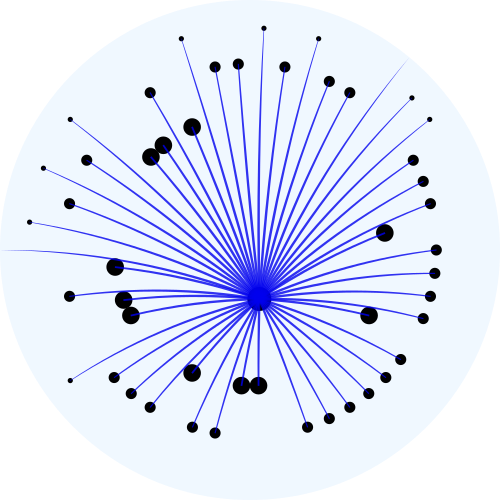

In [ ]:
Pdisk_G_c

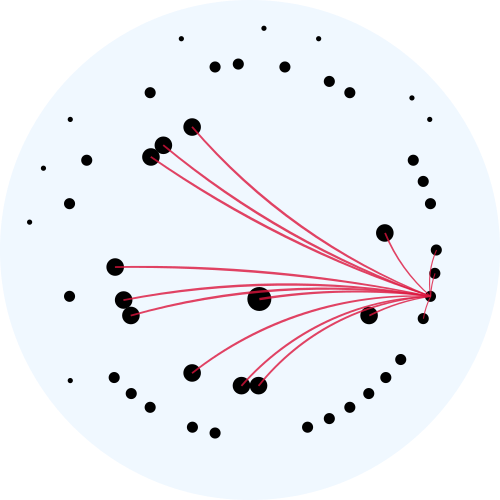

In [ ]:
Pdisk_G_p

## 2) Embed and Plot soft configuration

In [ ]:
G = nx.geometric_soft_configuration_graph(beta=1.5, n=100, gamma=2.7, mean_degree=5)

In [ ]:
nodelist = list(G.nodes())

A = nx.to_numpy_array(G, nodelist=nodelist, weight="weight", dtype=float)

In [ ]:

def weight_to_distance(A, eps=1e-12, diagonal_zero=True):
    """
    Convert positive affinities/weights to distances using

        d = -log(w / (1 + w))

    equivalent to

        d = log(1 + 1/w)

    Properties:
    - w -> infinity  => d -> 0
    - w -> 0+        => d -> infinity

    Parameters
    ----------
    A : ndarray
        Weight matrix with A_ij > 0 for i != j.
    eps : float
        Small floor to avoid division/log issues.
    diagonal_zero : bool
        Whether to force D_ii = 0.

    Returns
    -------
    D : ndarray
        Distance/dissimilarity matrix.
    """
    A = np.asarray(A, dtype=float)

    # clip strictly positive values
    A_safe = np.clip(A, eps, None)

    D = -np.log(A_safe / (1.0 + A_safe))

    if diagonal_zero:
        np.fill_diagonal(D, 0.0)

    return D

In [ ]:
D = weight_to_distance(A)

In [ ]:
from hypnetperturb.embedding.hyperboloid_embedding import *
from hypnetperturb.embedding.visualization import *

# 3. estimate optimal radius
r_opt, _ = estimate_r_opt_hyperbolic_1(D)

# 4. Wilson exact hyperbolic embedding
X_hyp, D_emb = hyperbolic_embedding(D, r_opt)

In [ ]:
plot_hyperbolic_embedding_px(X_hyp, r_opt, colors=true_colors, sizes=len(coords_disk)*[10])

R =  0.2499526291792175
[0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]


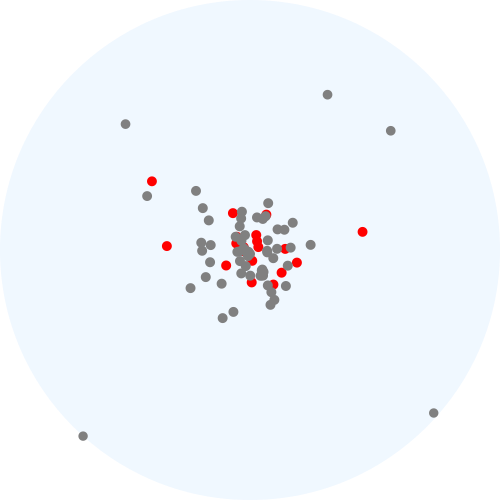

In [ ]:
# 5. project to Poincare disk
Y_disk = hyperboloid_to_Pdisk(X_hyp)
#X_unit = hyperboloid_to_unit_disk(X_hyp)

plot_Pdisk_embedding(Y_disk, node_colors=true_colors, sizes=len(coords_disk)*[0.01])